# 06 · Drift, fraudster adaptation and customer harm by age

1. **Drift:** does the 2019 model get worse month by month? Does retraining help?
2. **Fraudster adaptation:** what if criminals start keeping amounts small to dodge the model?
3. **Customer harm by age (Consumer Duty):** who gets wrongly declined or asked for passcodes, and who is targeted by fraud?

Run cells one at a time. Cell 3 retrains a model (2–4 minutes).

In [1]:
# 1. Load features, the 2019 model and the policy
import json, os, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

f = pd.read_parquet("data/clean/features.parquet")
num = ["amt", "amt_vs_usual", "txn_last_1h", "txn_last_24h", "spend_last_24h", "secs_since_prev",
       "new_merchant", "new_category", "distance_km", "age", "is_night", "hour"]
X = pd.get_dummies(f[num + ["category", "gender"]], columns=["category", "gender"], drop_first=True, dtype=int)
y = f["is_fraud"]
tr, va, te = (f["period"] == "train"), (f["period"] == "valid"), (f["period"] == "test")
model_2019 = joblib.load("data/clean/model_gb.joblib")
P = json.load(open("outputs/best_policy.json"))
os.makedirs("outputs", exist_ok=True)

def caught_top1(y_true, score):
    k = max(int(len(score) * 0.01), 1)
    top = np.argsort(-np.asarray(score))[:k]
    return np.asarray(y_true)[top].sum() / np.asarray(y_true).sum() * 100
print("Loaded ✅", X.shape)

Loaded ✅ (1852394, 26)


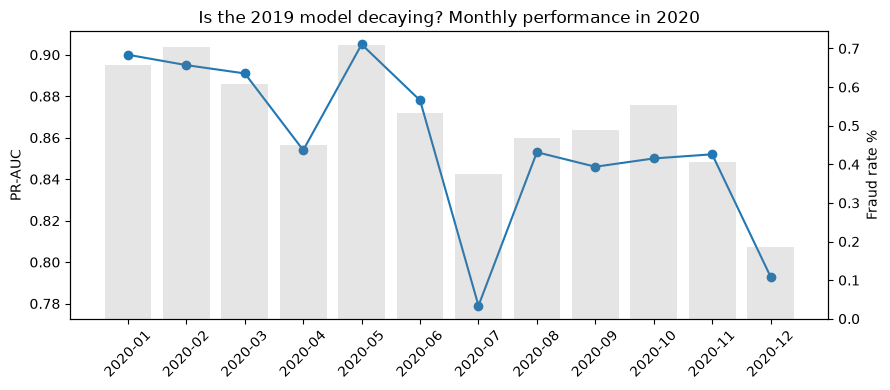

,month,fraud_rate_%,PR_AUC,fraud_caught_top1%
0,2020-01,0.657,0.900,91.545
1,2020-02,0.703,0.895,91.964
2,2020-03,0.609,0.891,91.892
3,2020-04,0.451,0.854,90.397
4,2020-05,0.709,0.905,93.928
5,2020-06,0.532,0.878,91.221
6,2020-07,0.374,0.779,85.981
7,2020-08,0.468,0.853,90.602
8,2020-09,0.489,0.846,89.118
9,2020-10,0.554,0.850,89.844


In [2]:
# 2. Drift: how does the 2019 model perform month by month in 2020?
f["month"] = f["ts"].dt.to_period("M").astype(str)
f["score_2019"] = model_2019.predict_proba(X)[:, 1]
monthly = []
for m, g in f[va | te].groupby("month"):
    monthly.append({"month": m, "fraud_rate_%": g["is_fraud"].mean() * 100,
                    "PR_AUC": average_precision_score(g["is_fraud"], g["score_2019"]),
                    "fraud_caught_top1%": caught_top1(g["is_fraud"], g["score_2019"])})
monthly = pd.DataFrame(monthly).round(3)
monthly.to_csv("outputs/drift_monthly.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly["month"], monthly["PR_AUC"], marker="o", label="PR-AUC (2019 model)")
ax2 = ax.twinx(); ax2.bar(monthly["month"], monthly["fraud_rate_%"], alpha=0.2, color="gray", label="Fraud rate %")
ax.set_title("Is the 2019 model decaying? Monthly performance in 2020"); ax.set_ylabel("PR-AUC"); ax2.set_ylabel("Fraud rate %")
ax.tick_params(axis="x", rotation=45); fig.tight_layout(); plt.savefig("outputs/drift_monthly.png", dpi=150); plt.show()
monthly

In [3]:
# 3. Retraining: model trained once on 2019 vs retrained on 2019 + Jan-Jun 2020. Both judged on Jul-Dec 2020.
model_retrained = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=42).fit(X[tr | va], y[tr | va])
s_static, s_retrained = model_2019.predict_proba(X[te])[:, 1], model_retrained.predict_proba(X[te])[:, 1]
retrain = pd.DataFrame({
    "model": ["Trained once (2019)", "Retrained (2019 + H1 2020)"],
    "PR_AUC_test": [average_precision_score(y[te], s_static), average_precision_score(y[te], s_retrained)],
    "fraud_caught_top1%_test": [caught_top1(y[te], s_static), caught_top1(y[te], s_retrained)]}).round(3)
retrain.to_csv("outputs/retraining.csv", index=False)
retrain

,model,PR_AUC_test,fraud_caught_top1%_test
0,Trained once (2019),0.828,90.109
1,Retrained (2019 + H1 2020),0.805,87.823


In [4]:
# 4. Fraudster adaptation: criminals split thefts into smaller payments.
#    We shrink fraud amounts (and the amount-based features) in the TEST months and re-score with the same model.
rows = []
for shrink in [1.0, 0.5, 0.25, 0.1]:
    Xa = X[te].copy()
    fr = (y[te] == 1).values
    for col in ["amt", "amt_vs_usual", "spend_last_24h"]:
        Xa.loc[fr, col] = Xa.loc[fr, col] * shrink
    sc = model_2019.predict_proba(Xa)[:, 1]
    rows.append({"fraud amounts x": shrink,
                 "fraud_caught_top1%": caught_top1(y[te], sc),
                 "fraud_txns_declined_%": (sc[fr] >= P["t_decline"]).mean() * 100,
                 "fraud_txns_declined_or_stepped_up_%": (sc[fr] >= P["t_step"]).mean() * 100})
adapt = pd.DataFrame(rows).round(2)
adapt.to_csv("outputs/fraudster_adaptation.csv", index=False)
adapt

,fraud amounts x,fraud_caught_top1%,fraud_txns_declined_%,fraud_txns_declined_or_stepped_up_%
0,1.00,90.11,85.39,90.41
1,0.50,45.63,29.52,45.38
2,0.25,11.38,10.64,11.33
3,0.10,8.50,8.50,8.50


In [5]:
# 5. Customer harm and fraud exposure by age (test months, current policy)
t = f[te].copy()
t["action"] = np.select([t["score_2019"] >= P["t_decline"], t["score_2019"] >= P["t_step"]], ["decline", "step_up"], "approve")
t["age_band"] = pd.cut(t["age"], [0, 30, 45, 60, 75, 120], labels=["Under 30", "30-44", "45-59", "60-74", "75+"], right=False)

def by_age(g):
    gen, fr = g[g["is_fraud"] == 0], g[g["is_fraud"] == 1]
    return pd.Series({
        "transactions": len(g),
        "fraud_rate_%": g["is_fraud"].mean() * 100,
        "fraud_value_£": fr["amt"].sum(),
        "fraud_caught_%": (fr["action"] != "approve").mean() * 100 if len(fr) else np.nan,
        "genuine_declined_per_10k": (gen["action"] == "decline").mean() * 10_000,
        "genuine_stepped_up_per_10k": (gen["action"] == "step_up").mean() * 10_000})
age = t.groupby("age_band", observed=True).apply(by_age).round(2)
age.to_csv("outputs/harm_by_age.csv")
age

,transactions,fraud_rate_%,fraud_value_£,fraud_caught_%,genuine_declined_per_10k,genuine_stepped_up_per_10k
age_band,,,,,,
Under 30,88001.0,0.35,167387.17,93.53,12.89,79.82
30-44,175166.0,0.35,298695.59,87.66,12.32,71.55
45-59,145709.0,0.39,299429.79,90.00,17.50,66.01
60-74,75736.0,0.48,199161.64,91.67,7.69,58.51
75+,41049.0,0.40,95375.56,93.33,7.58,54.06
